<a href="https://colab.research.google.com/github/oliviaberset/2026_Intro_Python/blob/main/live/part-I/1.3-numpy-environmental-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.3-numpy-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"gsw": "gsw", "pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import numpy as `np`, and encode units in your variable names.

## Exercise 1: Ocean float profiles

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/argo-float-cycle.png" alt="A diagram of one Argo float cycle, numbered one to seven, from deployment through drift, dive, ascent and satellite transmission" width="100%">

<em>One cycle of an Argo float: deployment, descent to a drifting depth of about 1000 m, ten days of
drift, a dive to the profiling depth, then the ascent during which the measurements are taken, and
transmission to satellite at the surface before the next cycle begins. The panel on the right shows
what one ascent produces — the temperature and salinity profiles you are about to work with.
Illustration &copy; Thomas Haessig, from
<a href="https://www.euro-argo.eu/Outreach/Educational-material/Discover-Argo-floats-for-kids/How-do-the-Argo-floats-fulfill-their-mission-in-the-Ocean">Euro-Argo ERIC's educational material</a>.</em>


[Argo](https://argo.ucsd.edu/) floats are autonomous instruments that drift with ocean currents,
periodically diving and surfacing while recording temperature, salinity, and pressure. Each dive
produces one *profile*: a set of measurements at many depth *levels*, with a single latitude,
longitude, and date attached.

This exercise uses real Argo data. Steps 1 to 8 use only what 1.1 to 1.3 cover: loading
arrays, inspecting shapes, rebuilding an axis, vectorised arithmetic, reductions along an axis,
boolean masks, and NaN-aware statistics. Steps 9 to 11 then plot what you computed.

**ℹ️ Beyond this subchapter**

Steps 9 to 11 use `matplotlib`, which gets its own treatment in 1.4. Import it once with
`import matplotlib.pyplot as plt`; after that you need only the functions below, and each is
named again where it is wanted:

- `plt.figure()` — start a new, empty figure; without it, every plot in a cell lands on the
  same axes
- [`plt.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html) — a line, or
  one line per column when handed a 2D array
- [`plt.errorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.errorbar.html) — a
  line with error bars
- [`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) — points
- `plt.xlabel`, `plt.ylabel`, `plt.title` — each takes a string
- `plt.show()` — draw the current figure

An array of numbers with no picture attached is hard to sanity-check, which is why these three
steps sit here rather than waiting for 1.4: the profiles are the fastest way to see whether Steps 4
to 6 produced something physical.

In [2]:
# Pre-supplied: download and unzip the Argo data files.
import pooch

files = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/argo_float_data.zip",
    known_hash="sha256:dd913ba3450241bcd5d5697187ea68d398bdd7fd563a04cc74386834749c25f5",
    processor=pooch.Unzip(),
    path=pooch.os_cache("mlees"),
)
for f in sorted(files):
    print(f)

Unzipping contents of '/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip' to '/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip'


/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/P.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/S.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/T.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/date.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lat.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/levels.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lon.npy


**Step 1.** Load each `.npy` file into a numpy array with `np.load`. Name them `T` (temperature,
°C), `S` (practical salinity, unitless), `P` (pressure, dbar), `date`, `lat`, `lon`, and `level` (depth level).

Read the filenames printed above to work out which file is which.

In [ ]:
# Your solution here
# Hint: every file sits in the same folder, Path(files[0]).parent (Path comes from pathlib)
# Hint: join a filename onto that folder with /, as in Path("_files") / "station_daily.csv"
# Hint: np.load(path) returns the array stored in a .npy file

In [7]:
import numpy as np
from pathlib import Path

folder_path = Path(files[0]).parent
P = np.load(folder_path/"P.npy")
S = np.load(folder_path/"S.npy")
T = np.load(folder_path/"T.npy")
date = np.load(folder_path/"date.npy")
lat = np.load(folder_path/"lat.npy")
levels = np.load(folder_path/"levels.npy")
lon = np.load(folder_path/"lon.npy")


**Step 2.** Print the `shape` of every array you loaded. Then answer in a comment: which
dimension do `T`, `S`, and `P` share with `level`, and which do they share with `lat`, `lon`,
and `date`?

In [ ]:
# Your solution here
# Hint: the profile arrays are two-dimensional; the coordinate arrays are one-dimensional
# Hint: a 2D array's shape tells you the length of each axis — match those against the 1D shapes

In [10]:
print(f"Shape of array:\n P: {P.shape}\n S: {S.shape}\n T:{T.shape}\n date: {date.shape}\n lat: {lat.shape}\n levels: {levels.shape}\n lon: {lon.shape}")

print(f"T, S & P share the axe 0 with levels and the axe 1 with date, lat and lon")

Shape of array:
 P: (78, 75)
 S: (78, 75)
 T:(78, 75)
 date: (75,)
 lat: (75,)
 levels: (78,)
 lon: (75,)
T, S & P share the axe 0 with levels and the axe 1 with date, lat and lon


**Step 3.** The `level` array is a regular sequence. Recreate it twice — once with `np.arange`
and once with `np.linspace` — and confirm each matches the original using `np.allclose`.

Read `level[0]`, `level[-1]`, and `level.size` first to work out the arguments.

In [ ]:
# Your solution here
# Hint: np.arange(start, stop, step) excludes the stop value
# Hint: np.linspace(start, stop, num) includes both ends
# Hint: np.allclose(a, b) returns True when every pair of elements is close enough

In [21]:
import numpy as np

print(levels[0], levels[-1], levels.size)

levels_nparange = np.arange(78)
print(levels_nparange)

levels_linspace = np.linspace(0, 77, 78)
print(levels_linspace)

print(np.allclose(levels_nparange, levels_linspace))

0 77 78
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77]
[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
 54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65. 66. 67. 68. 69. 70. 71.
 72. 73. 74. 75. 76. 77.]
True


**Step 4.** Compute the density of seawater relative to pure water, in kg m⁻³:

$$\rho - \rho_{\text{pure water}} = a\,S + b\,\Theta + c\,\Theta^{2}$$

where $S$ is salinity and $\Theta$ is the *conservative* temperature, computed from
temperature, salinity, and pressure by the `gsw` library. The constants are

```python
a = 7.718e-1
b = -8.44e-2
c = -4.561e-3
```

The cell below imports the function. Compute `conservative_temp` and `relative_density`, print
the shape of your result, and check it matches `T`.

Both `CT_from_t` and the formula expect *absolute* salinity, in g/kg, while Argo reports
*practical* salinity, which has no unit. Absolute salinity is about 0.5 % larger; for these
profiles, using practical salinity in its place lowers every relative density by about
0.13 kg m⁻³, which is small enough to ignore here. `gsw.SA_from_SP` does the exact conversion
when it matters.

Source: Roquet et al. (2015), *J. Phys. Oceanogr.* 45, 2564–2579, and the
[TEOS-10 GSW toolbox](https://www.teos-10.org/).

In [25]:
# Pre-supplied: the conservative-temperature function from the gsw library
from gsw import CT_from_t

In [26]:
# Your solution here
# Hint: CT_from_t(SA, t, p) takes salinity, temperature, and pressure — in that order
# Hint: the whole formula is one vectorised expression; no loop is needed
# Hint: Theta**2 squares every element

In [34]:
import gsw

conservative_temp = CT_from_t(S, T, P)
relative_density = gsw.SA_from_SP(S, P, lon, lat)
#realtive_density = conservative_temp - T

result = conservative_temp + relative_density
print(result.shape)

(78, 75)


**Step 5.** Compute the mean and the standard deviation of `T`, `S`, `P`, and
`relative_density` **at each depth**, averaging across all the profiles.

Check your result has the same shape as `level` — if it does not, you reduced along the wrong
axis.

In [ ]:
# Your solution here
# Hint: pick the axis that runs across profiles, not across depths
# Hint: mean_T.shape should equal level.shape

In [44]:
mean_T = np.mean(T, axis = 1)
mean_S = np.mean(S, axis=1)
mean_P = np.mean(P, axis=1)
mean_relative_density = np.mean(relative_density, axis=1)

std_T = np.std(T, axis = 1)
std_S = np.std(S, axis = 1)
std_P = np.std(P, axis = 1)
std_relative_density = np.std(relative_density)

print(f"mean % standard deviation:\n T: {mean_T}, {std_T}\n S: {mean_S}, {std_S}\n P: {mean_P}, {std_P}\n relative density: {mean_relative_density}, {stand_dev_relative_density}")

mean % standard deviation:
 T: [        nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan         nan         nan
         nan         nan         nan         nan 10.80430666 10.49702667
 10.1749066   9.83453334  9.48625332  9.19793334  8.66010666  8.12324001
  7.60221333  7.15289333  6.74250667  6.39543999  6.04598667  5.74538665
  5.48913333  5.26604001  5.08768     4.93479998  4.77769334  4.65368
  4.54237334  4.44274664  4.35933333         nan         nan         nan
         nan         nan         nan         nan         nan         nan], [       nan        na

**Step 6.** Look at the mean you just computed. Many entries are `nan`, because Argo profiles
contain missing values and an ordinary mean propagates them.

1. Count how many values in `T` are missing, using `np.isnan` and a sum over the boolean mask.
2. Express that as a percentage of all values in `T`.
3. Recompute the mean and standard deviation with `np.nanmean` and `np.nanstd`, and confirm no
   `nan` remains.

In [ ]:
# Your solution here
# Hint: np.isnan(T) gives a boolean array; True counts as 1 when summed
# Hint: T.size is the total number of elements
# Hint: np.isnan(result).sum() counts the nan that survived; it should be 0

In [58]:
missing_T_values = np.isnan(T).sum()
print(f"Number of missing values in T: {missing_T_values}")

print(f"Number of values in T: {T.size}")

missing_values_per = (missing_T_values / T.size)*100
print(f"percentage of missing values in T: {missing_values_per:.2f}%")

mean_T_2 = np.nanmean(T, axis=1)
std_T_2 = np.nanstd(T, axis=1)
print(f"Mean and standard deviation:\n {mean_T_2}, {std_T_2}")


Number of missing values in T: 101
Number of values in T: 5850
percentage of missing values in T: 1.73%
Mean and standard deviation:
 [17.60172602 17.57223609 17.5145833  17.42326395 17.24943838 17.03730134
 16.76787661 16.44609588 16.17439195 16.04501356 15.65827023 15.4607296
 15.26114862 15.12489191 14.99133783 14.90160808 14.81990544 14.74535139
 14.66822971 14.585027   14.49732434 14.41904053 14.35412163 14.27102702
 14.19081082 14.11487838 14.04347293 13.98067566 13.90994595 13.83274319
 13.76139196 13.69836479 13.62335132 13.54185131 13.46647295 13.39395946
 13.32541891 13.25205403 13.18131082 13.10233782 12.89268916 12.67795943
 12.4649189  12.2178513  11.98270268 11.1281081  10.80430666 10.49702667
 10.1749066   9.83453334  9.48625332  9.19793334  8.66010666  8.12324001
  7.60221333  7.15289333  6.74250667  6.39543999  6.04598667  5.74538665
  5.48913333  5.26604001  5.08768     4.93479998  4.77769334  4.65368
  4.54237334  4.44274664  4.35933333  4.2653784   4.17290539  4.089

**Step 7.** Using `np.where`, build an array that labels each depth `"warm"` where the mean
temperature there is above 10 °C and `"cold"` otherwise. Print the first ten labels alongside
the first ten depths.

Then, using a boolean mask, print the depths at which the mean temperature is below 5 °C.

In [ ]:
# Your solution here
# Hint: np.where(condition, value_if_true, value_if_false) works element-wise
# Hint: level[mask] selects the depths where the mask is True

In [69]:
labels = np.where(mean_T > 10.0, "warm", "cold")

for depth, label in zip(levels[:11], labels[:11]):
    print(depth, label)

mask = mean_T < 5.0
print(levels[mask])

0 cold
1 cold
2 cold
3 cold
4 cold
5 cold
6 cold
7 cold
8 cold
9 cold
10 cold
[63 64 65 66 67 68]


**Step 8.** Assemble a summary array with `np.vstack`: one row of depths, one of mean
temperature, one of mean salinity, and one of mean relative density — four rows in total.

Print its shape, save it to `_files/argo_summary.npy`, load it back, and confirm with `np.allclose`
that the round trip changed nothing.

In [ ]:
# Your solution here
# Hint: np.vstack takes a list of 1D arrays and stacks them as rows
# Hint: your summary should have shape (4, n_levels)
# Hint: _files/ may not exist yet; create it first with Path("_files").mkdir(exist_ok=True)

In [81]:
from pathlib import Path
import numpy as np

summary_array = np.vstack((levels, mean_T, mean_S, mean_relative_density))
print(summary_array.shape)

path_file=Path("_files/argo_summary.npy")
path_file.parent.mkdir(exist_ok=True)

np.save(path_file, summary_array)

summary_loaded = np.load(path_file)
print(summary_loaded.shape)

print(np.allclose(summary_array, summary_loaded))


(4, 78)
(4, 78)
False


**Step 9.** Plot each of `T`, `S`, `P` and `relative_density` against depth — four figures, one
per variable.

Each array is `(level, profile)`, so handing the whole array to `plt.plot` draws one line per
profile. Put the variable on the *x*-axis and `level` on the *y*-axis, which is the oceanographic
convention: depth runs down the page, and a profile is read the way the float measured it.

It will look messy, because 75 profiles are drawn on top of each other.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.3-target-argo-profiles.png" alt="Many overlapping salinity profiles plotted against depth level, forming a dense band that shifts towards fresher water with depth" width="500">

<em>The salinity panel, as a check on yours. Label the axes and give each figure a title.</em>

In [ ]:
# Your solution here
# Hint: plt.figure() before each variable's plot, plt.show() after it
# Hint: plt.plot(S, level) draws one line per column of S
# Hint: the semicolon at the end of a plt.plot call suppresses the list of line objects
# Hint: plt.xlabel, plt.ylabel and plt.title each take a string

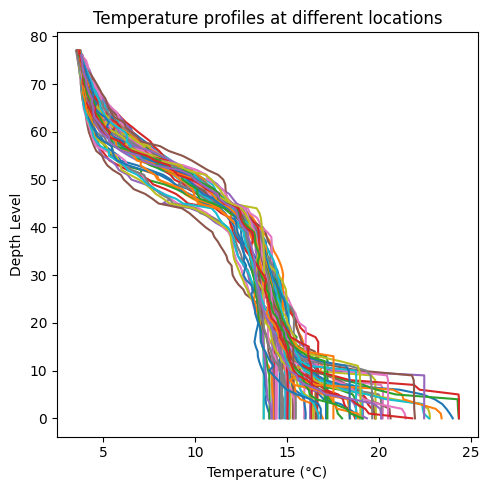

In [100]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(T, levels)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Depth Level")
ax.set_title("Temperature profiles at different locations")

plt.tight_layout()
plt.show()


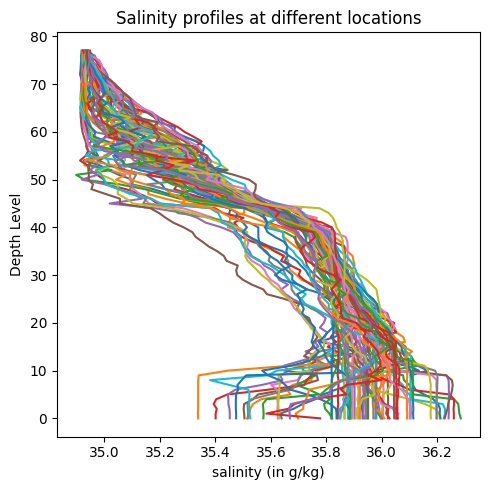

In [99]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(S, levels)
ax.set_xlabel("salinity (in g/kg)")
ax.set_ylabel("Depth Level")
ax.set_title("Salinity profiles at different locations")

plt.tight_layout()
plt.show()


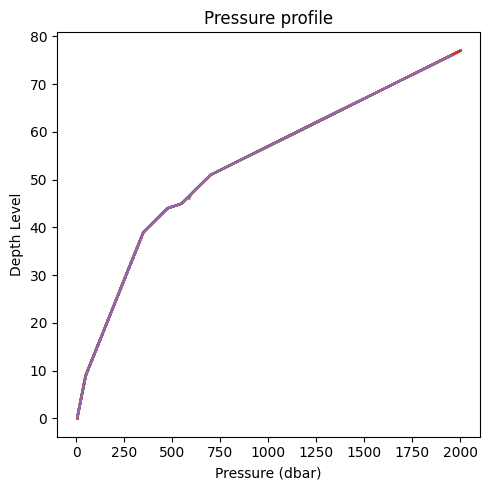

In [98]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(P, levels)
ax.set_xlabel("Pressure (dbar)")
ax.set_ylabel("Depth Level")
ax.set_title("Pressure profile")

plt.tight_layout()
plt.show()

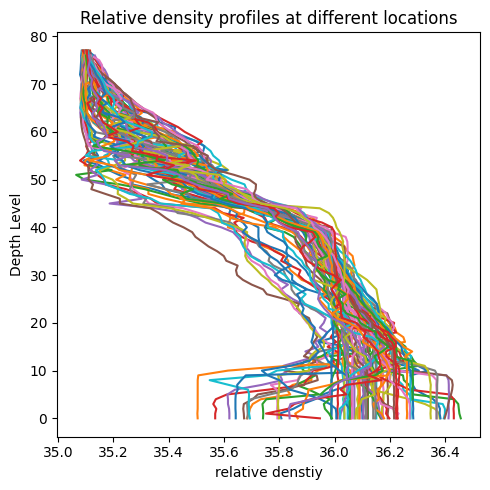

In [97]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(relative_density, levels)
ax.set_xlabel("relative denstiy")
ax.set_ylabel("Depth Level")
ax.set_title("Relative density profiles at different locations")

plt.tight_layout()
plt.show()


**Step 10.** Now plot only the *mean* profile of each variable, with the standard deviation as
error bars.

Use the NaN-aware mean and standard deviation from Step 6, and draw them with `plt.errorbar`.
Because the variable is on the *x*-axis, the spread is a *horizontal* error bar — the keyword is
`xerr`, not `yerr`.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.3-target-argo-mean-profiles.png" alt="A single mean salinity profile against depth level with horizontal error bars at each level" width="500">

<em>The salinity panel again, reduced from 75 profiles to one line and its spread.</em>


In a comment, say what the width of the error bars tells you about how much the profiles disagree
near the surface compared with at depth.

In [ ]:
# Your solution here
# Hint: plt.errorbar(mean_S, level, xerr=std_S)
# Hint: use the nan-aware versions from Step 6, or every bar will be missing

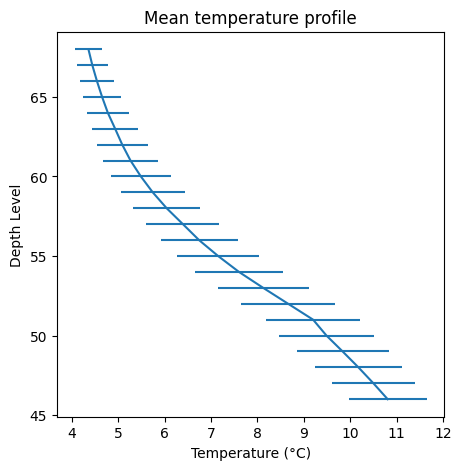

In [111]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))
ax.errorbar(mean_T, levels, xerr=std_T)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Depth Level")
ax.set_title("Mean temperature profile")

plt.show()

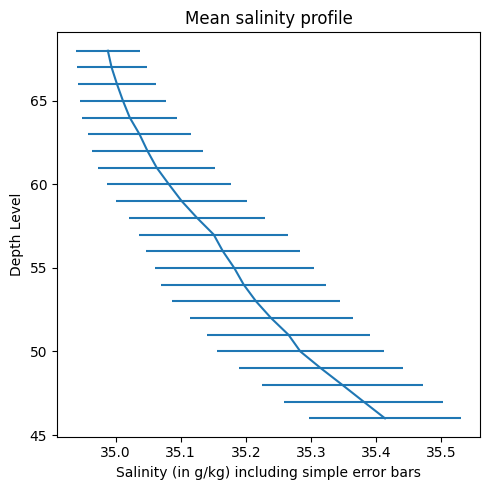

In [109]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))
ax.errorbar(mean_S, levels, xerr=std_S)
ax.set_xlabel("Salinity (in g/kg) including simple error bars")
ax.set_ylabel("Depth Level")
ax.set_title("Mean salinity profile")

plt.tight_layout()
plt.show()

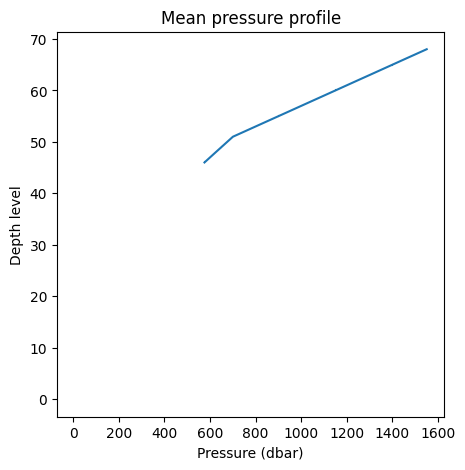

In [113]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))
ax.errorbar(mean_P, levels, xerr=std_P)
ax.set_xlabel("Pressure (dbar)")
ax.set_ylabel("Depth level")
ax.set_title("Mean pressure profile")

plt.show()

Text(0.5, 1.0, 'relative density mean profile')

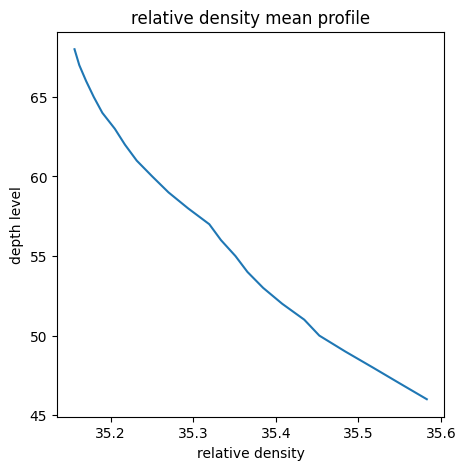

In [114]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))
ax.errorbar(mean_relative_density, levels, xerr=std_relative_density)
ax.set_xlabel("relative density")
ax.set_ylabel("depth level")
ax.set_title("relative density mean profile")


**Step 11.** Scatter the profiles' longitudes against their latitudes.

One point per profile. Label both axes and give it a title, and set the marker size with `s=` so
the points are readable. Then print the first three entries of `date` and the last one.

In a comment, say what the dates and the shape of the cloud tell you about how this set of
profiles was collected, and by how many floats.

In [ ]:
# Your solution here
# Hint: plt.scatter(lon, lat)
# Hint: lon and lat have one entry per profile, not per level
# Hint: look at the spacing between consecutive dates

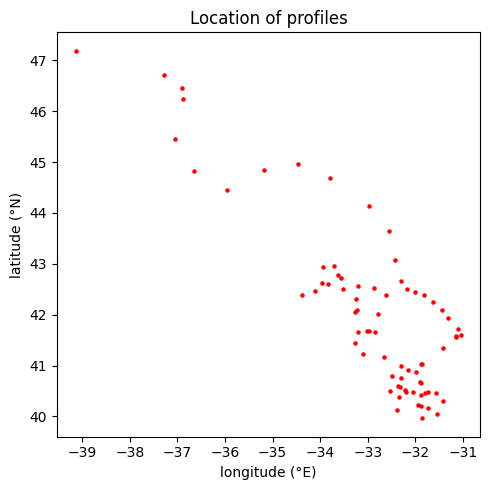

Three first entries of date: ['2012-07-13T22:33:06.019200000' '2012-07-23T22:54:59.990400000'
 '2012-08-02T22:55:52.003200000']
Last entry of date: 2014-07-24T03:02:33.014400000


In [128]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(lon, lat, s=5, color="r")
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Location of profiles")

plt.tight_layout()
plt.show()

print(f"Three first entries of date: {date[:3]}")
print(f"Last entry of date: {date[-1]}")

**ℹ️ What you just did**

You loaded a real oceanographic dataset, worked out its structure from the array shapes alone,
rebuilt a coordinate axis and verified it, evaluated a published equation of state as one
vectorised expression over 5,850 measurements (78 depth levels by 75 profiles), reduced along the
right axis, counted the missing values and switched to NaN-aware statistics, and saved a derived
product.

None of the computation needed a loop over the data. In the next subchapter `xarray` attaches the
names (depth, profile, latitude) to the axes you have been tracking by hand, and `matplotlib` gets
its full treatment, including the line, error-bar and scatter plots you drew here.